# Clustering assumptions on real data

`ClusteringAssumptionsChecker` asks: *given the characteristics of this dataset, is this clustering algorithm a sensible choice?* It has no labels to go on, so it infers structure from the data. It looks for separated dense regions and tests whether K-Means or a Gaussian mixture reproduces them. It also checks noise, density, spread, dimensionality, scaling and repeated values.

This notebook runs it on three UCI datasets. For two of them, labels the checker never sees confirm what it finds. For synthetic data with known geometry (blobs, moons, circles), see `../clustering_examples.ipynb`.

| Dataset | What it shows |
|---|---|
| Online Retail (customer RFM) | Skewed counts and tied values; how a log transform changes the verdict |
| Human Activity Recognition | 561 features: high dimensions where K-Means still works |
| Estimation of Obesity Levels | Mixed data types, and a tight synthetic clump created by SMOTE |

In [1]:
import sys, io, contextlib, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))  # import the package from the repo root
from assumptions import ClusteringAssumptionsChecker

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
DATA = Path("../data")
MUTED, ACCENT = "#9aa5b1", "#2a6fdb"


def run_checker(df, **kwargs):
    """Run every check quietly and return the checker."""
    checker = ClusteringAssumptionsChecker(df, **kwargs)
    with contextlib.redirect_stdout(io.StringIO()):
        checker.check_assumptions()
    return checker


def findings(checker, keys=("tied_values", "outliers", "dimensionality", "clustering_tendency",
                            "cluster_shape", "cluster_variance", "density_variation")):
    """The diagnostic notes, one per check."""
    return pd.Series({k: checker.results[k]["notes"] for k in keys}, name="finding").to_frame()


def ranking(checker):
    """Suitability and headline reason for every algorithm, best first."""
    return pd.DataFrame(checker.report["recommendations"])[["algorithm", "suitability", "reason"]]

## 1. Online Retail: customer segmentation with RFM

The raw data has one row per invoice line. The standard segmentation approach summarises each customer by **R**ecency (days since last purchase), **F**requency (number of invoices) and **M**onetary value (total spend). Loading the spreadsheet takes about 30 seconds.

In [2]:
retail = pd.read_excel(DATA / "online+retail" / "Online Retail.xlsx")
retail = retail.dropna(subset=["CustomerID"])
retail = retail[(retail["Quantity"] > 0) & (retail["UnitPrice"] > 0)]   # drop returns and adjustments
retail["Revenue"] = retail["Quantity"] * retail["UnitPrice"]

snapshot = retail["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = retail.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)
rfm.describe().round(1)

,Recency,Frequency,Monetary
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2054.3
std,100.0,7.7,8989.2
min,1.0,1.0,3.8
25%,18.0,1.0,307.4
50%,51.0,2.0,674.5
75%,142.0,5.0,1661.7
max,374.0,209.0,280206.0


### Raw RFM

Spend runs from £4 to £280,000, and a third of customers bought exactly once.

In [3]:
raw = run_checker(rfm)
findings(raw)

,finding
tied_values,1 of 3 numeric columns repeat one value heavily (most common value's share: Frequency (34%)); stacked points form artificial dense slices.
outliers,2.1% of points are local outliers (LOF > 2.0).
dimensionality,3 features; distances discriminate well (CV 1.61).
clustering_tendency,Hopkins statistic 0.98: the data has clear cluster structure.
cluster_shape,4 separated dense regions that neither K-Means (ARI 0.10) nor a Gaussian mixture (ARI 0.14) reproduces: clusters are non-convex or other...
cluster_variance,"Clusters aren't blob-shaped, so Gaussian components don't correspond to clusters and their spreads aren't comparable."
density_variation,Typical neighbour spacing differs 3.4× between dense regions: clusters have different densities.


In [4]:
ranking(raw)

,algorithm,suitability,reason
0,OPTICS,high,"Density-based like DBSCAN, but copes with clusters of different densities."
1,DBSCAN,medium,Cluster densities differ (3.37× neighbour spacing); a single eps merges dense clusters or discards sparse ones as noise. OPTICS or HDBSC...
2,SpectralClustering,medium,"Cluster densities differ (3.37× neighbour spacing); a single RBF bandwidth fits them poorly, so try affinity='nearest_neighbors'."
3,AgglomerativeClustering,low,"Clusters are non-convex: use linkage='single' (ward, average and complete favour compact clusters), though single linkage chains through..."
4,KMeans,unsuitable,"Clusters are non-convex or not blob-shaped; K-Means only draws convex, roughly spherical clusters and cuts across them."
5,MiniBatchKMeans,unsuitable,"Clusters are non-convex or not blob-shaped; K-Means only draws convex, roughly spherical clusters and cuts across them."
6,GaussianMixture,unsuitable,"Clusters are non-convex or not blob-shaped; each Gaussian is an ellipsoid, so a mixture doesn't reproduce them."


The checker marks K-Means unsuitable, but its first caveat questions its own shape verdict:

In [5]:
for caveat in raw.report["caveats"]:
    print("•", caveat)

• The 'non_convex' shape verdict may come from repeated values in Frequency rather than real groups: check whether the dense regions are slices of those columns before ruling out K-Means.
• Standardise features before clustering: every algorithm here is distance- or variance-based.
• Validate the result: no single score proves clusters are real, so compare silhouette scores, stability across seeds or subsamples, and domain sense.


It is right to be suspicious. Three of the four dense regions are customers with `Frequency == 1` (34% of all customers), stacked on one value. They aren't natural segments. Monetary is also extremely skewed, so a few big spenders dominate any distance. The honest conclusion for raw RFM isn't "use OPTICS". It's that the features need transforming before any algorithm's verdict means much.

### Log-transformed RFM

The usual fix is a log transform, which compresses the long tails:

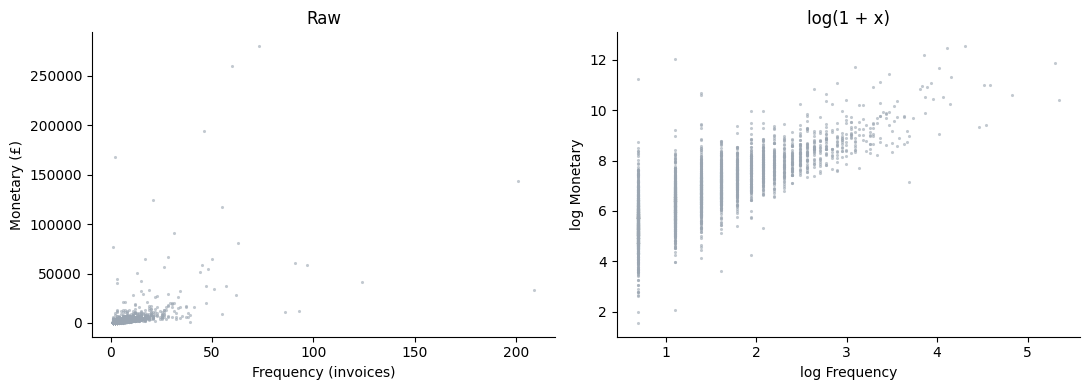

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(rfm["Frequency"], rfm["Monetary"], s=5, color=MUTED, alpha=0.6, linewidths=0)
axes[0].set(title="Raw", xlabel="Frequency (invoices)", ylabel="Monetary (£)")
log_rfm = np.log1p(rfm)
axes[1].scatter(log_rfm["Frequency"], log_rfm["Monetary"], s=5, color=MUTED, alpha=0.6, linewidths=0)
axes[1].set(title="log(1 + x)", xlabel="log Frequency", ylabel="log Monetary")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
logged = run_checker(log_rfm)
findings(logged)

,finding
tied_values,1 of 3 numeric columns repeat one value heavily (most common value's share: Frequency (34%)); stacked points form artificial dense slices.
outliers,No meaningful outliers detected.
dimensionality,3 features; distances discriminate well (CV 0.59).
clustering_tendency,Hopkins statistic 0.92: the data has clear cluster structure.
cluster_shape,"3 separated dense regions that K-Means doesn't reproduce (ARI 0.33), though clusters look round and similar in size: some regions probab..."
cluster_variance,A Gaussian mixture finds 10 clusters of similar spread (ratio 1.4×).
density_variation,Typical neighbour spacing differs 2.2× between dense regions: clusters have different densities.


In [8]:
ranking(logged)

,algorithm,suitability,reason
0,KMeans,high,"Fast, simple partitioning into compact clusters of similar size."
1,GaussianMixture,high,"Models clusters as ellipsoids of any orientation and size, with soft membership."
2,MiniBatchKMeans,medium,"Only 4,338 rows: standard KMeans is exact and fast enough."
3,AgglomerativeClustering,medium,Cluster densities differ (2.19× neighbour spacing); single linkage chains through the sparse clusters.
4,OPTICS,medium,"Clusters overlap or touch, so density-based methods tend to merge them into one."
5,SpectralClustering,medium,"Cluster densities differ (2.19× neighbour spacing); a single RBF bandwidth fits them poorly, so try affinity='nearest_neighbors'."
6,DBSCAN,low,"Clusters overlap or touch, so density-based methods tend to merge them into one."


After the log transform the outliers disappear, the Gaussian mixture finds clusters of similar spread, and K-Means rises to **high**. That supports the common recipe of log-scaled RFM followed by K-Means.

The checker still reports that the dense regions overlap or touch, and the vertical stripes in the right-hand plot show why: Frequency is still a count. Customer segments here are a convenient partition of a continuum, not natural groups, so DBSCAN and OPTICS (which look for gaps) are marked down.

## 2. Human Activity Recognition: 561 features

The data is smartphone accelerometer and gyroscope summaries from 30 people doing six activities. We use the 7,352 training windows and leave the activity labels out.

In [9]:
har_zip = zipfile.ZipFile(DATA / "human+activity+recognition+using+smartphones" / "UCI HAR Dataset.zip")
har = pd.read_csv(har_zip.open("UCI HAR Dataset/train/X_train.txt"), sep=r"\s+", header=None)
features = pd.read_csv(har_zip.open("UCI HAR Dataset/features.txt"), sep=r"\s+", header=None)[1]
har.columns = [f"{i}_{name}" for i, name in enumerate(features)]  # some feature names repeat
har.shape

(7352, 561)

In [10]:
har_checker = run_checker(har)
findings(har_checker)

,finding
tied_values,"A few columns repeat one value heavily (62_tGravityAcc-entropy()-X (42%), 63_tGravityAcc-entropy()-Y (74%), 64_tGravityAcc-entropy()-Z (..."
outliers,No meaningful outliers detected.
dimensionality,"561 features, but distances still discriminate (CV 0.38)."
clustering_tendency,Hopkins statistic 0.85: the data has clear cluster structure.
cluster_shape,"2 separated dense regions, which K-Means reproduces (ARI 1.00): clusters are compact enough for K-Means."
cluster_variance,A Gaussian mixture finds 10 clusters whose spreads differ by 2.8×. Elongation not assessed: with more than 10 features only diagonal cov...
density_variation,Clusters have similar density (neighbour spacing ratio 1.4× across dense regions).


In [11]:
ranking(har_checker)

,algorithm,suitability,reason
0,DBSCAN,high,Density-based: finds arbitrarily shaped clusters and labels noise.
1,OPTICS,high,"Density-based like DBSCAN, but copes with clusters of different densities."
2,GaussianMixture,high,"Models clusters as ellipsoids of any orientation and size, with soft membership."
3,SpectralClustering,high,Graph-based: recovers connected but non-convex clusters.
4,KMeans,medium,"Cluster spreads differ by 2.82×; K-Means puts boundaries midway between centroids, so wide clusters lose points."
5,AgglomerativeClustering,medium,Cluster spreads differ by 2.82×; ward linkage favours clusters of similar size.
6,MiniBatchKMeans,low,"Cluster spreads differ by 2.82×; K-Means puts boundaries midway between centroids, so wide clusters lose points."


A few things to notice:

- **Speed:** the geometric checks run on a 2,000-row sample, so 561 features take seconds, not minutes.
- **Dimensionality:** 561 features would normally raise concerns, but pairwise distances still discriminate (CV well above the 0.15 alarm level). The features are highly correlated, so the data effectively lives in far fewer dimensions.
- **Shape:** the checker finds two well-separated dense regions and K-Means reproduces them exactly. It marks K-Means down only because the clusters differ in spread.
- **Elongation** isn't assessed: with this many features only diagonal covariances are fitted.

### Checking against the labels the checker never saw

If the two dense regions are real, K-Means with `k=2` should recover something meaningful:

In [12]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

labels = pd.read_csv(har_zip.open("UCI HAR Dataset/train/y_train.txt"), header=None)[0]
names = pd.read_csv(har_zip.open("UCI HAR Dataset/activity_labels.txt"), sep=r"\s+", header=None, index_col=0)[1]
clusters = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(har))
pd.crosstab(labels.map(names).rename("activity"), pd.Series(clusters, name="K-Means cluster"))

K-Means cluster,0,1
activity,,
LAYING,1396,11
SITTING,1285,1
STANDING,1374,0
WALKING,0,1226
WALKING_DOWNSTAIRS,0,986
WALKING_UPSTAIRS,8,1065


It does: the two clusters are **static** activities (laying, sitting, standing) and **moving** ones (walking, upstairs, downstairs), with only 20 of 7,352 windows on the wrong side. Separating the six individual activities is a much harder problem. The checker's estimate of about 2 natural groups is an honest description of the data's structure, not a promise that unsupervised learning will recover all six labels.

A 2-D projection shows the same split:

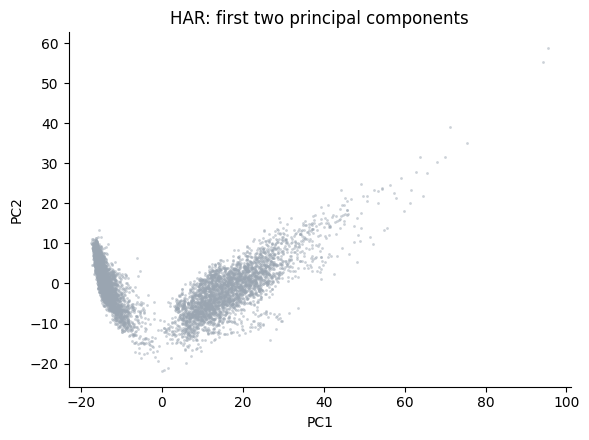

In [13]:
from sklearn.decomposition import PCA

projected = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(har))
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(projected[:, 0], projected[:, 1], s=4, color=MUTED, alpha=0.5, linewidths=0)
ax.set(title="HAR: first two principal components", xlabel="PC1", ylabel="PC2")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Estimation of Obesity Levels: mixed types and synthetic data

The data covers eating habits and physical condition for 2,111 people, with eight numeric and eight categorical columns. The UCI page notes that **77% of the rows are synthetic**, generated with SMOTE to balance the classes. We drop the target, `NObeyesdad`.

In [14]:
obesity = pd.read_csv(DATA / "estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition"
                      / "ObesityDataSet_raw_and_data_sinthetic.csv")
target = obesity.pop("NObeyesdad")
obesity.dtypes.value_counts()

object     8
float64    8
Name: count, dtype: int64

### All columns: the mixed-type warning

In [15]:
mixed = run_checker(obesity)
for caveat in mixed.report["caveats"]:
    print("•", caveat)
ranking(mixed)

• The 'non_convex' shape verdict may come from repeated values in FCVC, NCP, CH2O, TUE rather than real groups: check whether the dense regions are slices of those columns before ruling out K-Means.
• 8 non-numeric column(s) ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS'] were excluded from the geometric checks, which use the 8 numeric column(s).
• Standardise features before clustering: every algorithm here is distance- or variance-based.
• Validate the result: no single score proves clusters are real, so compare silhouette scores, stability across seeds or subsamples, and domain sense.


,algorithm,suitability,reason
0,OPTICS,medium,Non-numeric columns present: use metric='precomputed' with Gower distances.
1,AgglomerativeClustering,low,"Clusters are non-convex: use linkage='single' (ward, average and complete favour compact clusters), though single linkage chains through..."
2,DBSCAN,low,Cluster densities differ (3.78× neighbour spacing); a single eps merges dense clusters or discards sparse ones as noise. OPTICS or HDBSC...
3,SpectralClustering,low,"Cluster densities differ (3.78× neighbour spacing); a single RBF bandwidth fits them poorly, so try affinity='nearest_neighbors'."
4,KMeans,unsuitable,"Clusters are non-convex or not blob-shaped; K-Means only draws convex, roughly spherical clusters and cuts across them."
5,MiniBatchKMeans,unsuitable,"Clusters are non-convex or not blob-shaped; K-Means only draws convex, roughly spherical clusters and cuts across them."
6,GaussianMixture,unsuitable,"Clusters are non-convex or not blob-shaped; each Gaussian is an ellipsoid, so a mixture doesn't reproduce them."


None of these algorithms take categorical columns directly. The checker excludes them from the geometric checks and points to the options: one-hot encoding, Gower distances with `metric='precomputed'` (Agglomerative, DBSCAN, OPTICS), or K-Prototypes.

### Numeric columns only

In [16]:
numeric = run_checker(obesity.select_dtypes("number"))
findings(numeric)

,finding
tied_values,"4 of 8 numeric columns repeat one value heavily (most common value's share: FCVC (31%), NCP (57%), CH2O (21%), TUE (26%)); stacked point..."
outliers,No meaningful outliers detected.
dimensionality,8 features; distances discriminate well (CV 0.27).
clustering_tendency,Hopkins statistic 0.80: the data has clear cluster structure.
cluster_shape,2 separated dense regions that neither K-Means (ARI 0.01) nor a Gaussian mixture (ARI 0.38) reproduces: clusters are non-convex or other...
cluster_variance,"Clusters aren't blob-shaped, so Gaussian components don't correspond to clusters and their spreads aren't comparable."
density_variation,Typical neighbour spacing differs 3.8× between dense regions: clusters have different densities.


In [17]:
ranking(numeric)

,algorithm,suitability,reason
0,OPTICS,high,"Density-based like DBSCAN, but copes with clusters of different densities."
1,DBSCAN,medium,Cluster densities differ (3.78× neighbour spacing); a single eps merges dense clusters or discards sparse ones as noise. OPTICS or HDBSC...
2,SpectralClustering,medium,"Cluster densities differ (3.78× neighbour spacing); a single RBF bandwidth fits them poorly, so try affinity='nearest_neighbors'."
3,AgglomerativeClustering,low,"Clusters are non-convex: use linkage='single' (ward, average and complete favour compact clusters), though single linkage chains through..."
4,KMeans,unsuitable,"Clusters are non-convex or not blob-shaped; K-Means only draws convex, roughly spherical clusters and cuts across them."
5,MiniBatchKMeans,unsuitable,"Clusters are non-convex or not blob-shaped; K-Means only draws convex, roughly spherical clusters and cuts across them."
6,GaussianMixture,unsuitable,"Clusters are non-convex or not blob-shaped; each Gaussian is an ellipsoid, so a mixture doesn't reproduce them."


The checker finds a small, very dense region beside a diffuse cloud, which neither K-Means nor a Gaussian mixture reproduces. It also flags heavy repetition in the ordinal columns (FCVC, NCP, CH2O, TUE). Inspecting the region shows it is made of rows with FCVC = 3 and NCP = 3. How do those rows relate to the target?

In [18]:
clump = (obesity["FCVC"] == 3) & (obesity["NCP"] == 3)
pd.crosstab(target, clump.rename("FCVC == 3 and NCP == 3"))

FCVC == 3 and NCP == 3,False,True
NObeyesdad,,
Insufficient_Weight,244,28
Normal_Weight,206,81
Obesity_Type_I,330,21
Obesity_Type_II,291,6
Obesity_Type_III,0,324
Overweight_Level_I,274,16
Overweight_Level_II,268,22


In [19]:
type_iii = obesity[target == "Obesity_Type_III"]
type_iii[["Gender", "Age", "Height", "Weight", "FCVC", "NCP"]].describe(include="all").round(2)

,Gender,Age,Height,Weight,FCVC,NCP
count,324,324.00,324.00,324.00,324.0,324.0
unique,2,NaN,NaN,NaN,NaN,NaN
top,Female,NaN,NaN,NaN,NaN,NaN
freq,323,NaN,NaN,NaN,NaN,NaN
mean,NaN,23.50,1.69,120.94,3.0,3.0
std,NaN,2.76,0.07,15.53,0.0,0.0
min,NaN,18.00,1.56,102.00,3.0,3.0
25%,NaN,21.02,1.63,109.49,3.0,3.0
50%,NaN,25.37,1.67,112.05,3.0,3.0
75%,NaN,26.00,1.74,133.50,3.0,3.0


Every one of the 324 `Obesity_Type_III` rows has identical answers on two survey questions (FCVC = 3, NCP = 3). All but one are women, and all are aged 18 to 26. That uniformity is what you'd expect if SMOTE generated most of this class by interpolating between a few original respondents. The result is a tight synthetic clump.

The checker can't know where the data came from. It *can* see that this region is far denser and tighter than everything else, so it steers away from K-Means and towards density-based methods. This is also a warning about the data itself: a cluster found here may describe the oversampling procedure rather than a real population.

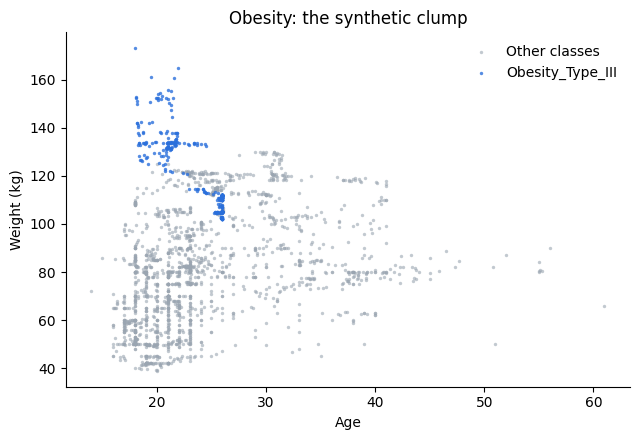

In [20]:
is_type_iii = target == "Obesity_Type_III"
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(obesity.loc[~is_type_iii, "Age"], obesity.loc[~is_type_iii, "Weight"], s=6, color=MUTED,
           alpha=0.6, linewidths=0, label="Other classes")
ax.scatter(obesity.loc[is_type_iii, "Age"], obesity.loc[is_type_iii, "Weight"], s=6, color=ACCENT,
           alpha=0.8, linewidths=0, label="Obesity_Type_III")
ax.set(title="Obesity: the synthetic clump", xlabel="Age", ylabel="Weight (kg)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Summary

| Dataset | Checker's verdict | Confirmed by |
|---|---|---|
| Online Retail, raw RFM | K-Means unsuitable, with a caveat that the verdict may come from tied values | It does: the dense regions are customers with a single purchase |
| Online Retail, log RFM | K-Means and GMM high; segments overlap rather than separate | Standard RFM practice |
| Human Activity Recognition | Two well-separated groups that K-Means reproduces, despite 561 features | Activity labels: static versus moving, 99.7% agreement |
| Obesity, numeric columns | A tight clump beside a diffuse cloud; K-Means and GMM fit poorly | The clump is the SMOTE-generated `Obesity_Type_III` class |

On every dataset the checker also reminds you to validate any clustering you fit. Its job is to say which algorithms are a sensible starting point, not to prove the clusters are real.